<a href="https://colab.research.google.com/github/hersil7/cdd_ucsc/blob/main/5_S4_Notebook_Laboratorio_CDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# #Este código oculta los mensajes de advertencia de la biblioteca jupyter_client

# import warnings

# warnings.filterwarnings(
#     "ignore",
#     category=DeprecationWarning,
#     message=r".*datetime\.datetime\.utcnow\(\).*"
# )

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_explorado.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | Hernán Silva |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 4/Lab4/'
SEMILLA = 20264
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# En Google Colab, mlxtend ya viene instalado. En local:
# !pip install mlxtend scikit-learn
print('Listo')

Listo


---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [ ]:
df = pd.read_csv(RUTA + '6-S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

Líneas: 21494 · Transacciones: 4000 · Productos: 21


,transaccion_id,fecha,tienda,producto
0,T00001,2025-03-02,Norte,pan
1,T00001,2025-03-02,Norte,vino
2,T00002,2025-06-22,Oriente,azucar
3,T00002,2025-06-22,Oriente,cafe
4,T00002,2025-06-22,Oriente,fideos


### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

In [ ]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]

Matriz: (4000, 21)


producto,arroz,azucar,cafe,cerveza,detergente,fideos
transaccion_id,,,,,,
T00001,False,False,False,False,False,False
T00002,False,True,True,False,False,True
T00003,False,True,False,True,False,False
T00004,True,False,False,False,False,False
T00005,False,True,False,False,False,False


In [ ]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(8).round(3)

,0
producto,
pan,0.622
leche,0.566
palta,0.462
azucar,0.321
salsa de tomate,0.304
huevos,0.294
jamon,0.240
arroz,0.238


«pan» aparece en el 62 % de las canastas y «leche» en el 57 %. **Retén ese dato**: explica lo que viene a continuación.

### 1.2 Extraer las reglas

In [ ]:
# %pip install "jupyter-client==7.4.9"

In [ ]:
!pip install --upgrade jupyter-client

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True) # Encontrar los conjuntos frecuentes con soporte mínimo del 5%
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10) # Generar reglas de asociación con confianza mínima del 10%

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer (longitud de antecedentes y consecuentes igual a 1)
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0])) # Crear una columna con la representación de la regla en formato "antecedente → consecuente"
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 205


### 1.3 La trampa: ordenar por confianza

In [ ]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
156,palta → pan,0.392,0.850,1.368
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
69,cerveza → papas fritas,0.098,0.667,2.830
75,detergente → pan,0.079,0.656,1.056
186,tomate → pan,0.133,0.645,1.038
56,cafe → pan,0.127,0.643,1.035
183,queso → pan,0.144,0.637,1.024


Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

### 1.4 El mismo cálculo, ordenado por lift

In [ ]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
68,papas fritas → cerveza,0.098,0.415,2.830
69,cerveza → papas fritas,0.098,0.667,2.830
201,queso → vino,0.064,0.280,2.743
202,vino → queso,0.064,0.623,2.743
88,salsa de tomate → fideos,0.172,0.566,2.573
89,fideos → salsa de tomate,0.172,0.783,2.573
20,cafe → azucar,0.147,0.747,2.327
21,azucar → cafe,0.147,0.458,2.327


Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

In [ ]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

pan → leche     soporte 0.344 · confianza 0.554 · lift 0.979
leche → pan     soporte 0.344 · confianza 0.608 · lift 0.979


`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [ ]:
# Tu código aquí
frecuentes = apriori(cesta, min_support=0.05, use_colnames=True) # Encontrar los conjuntos frecuentes con soporte mínimo del 5%
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10) # Generar reglas de asociación con confianza mínima del 10%

# nos quedamos con las reglas dos productos en el antecedente (`antecedents.str.len() == 2`)
reglas = reglas[(reglas['antecedents'].str.len() == 2) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: ', '.join(list(s))) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0])) # Crear una columna con la representación de la regla en formato "antecedente → consecuente"
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 189


In [ ]:
reglas

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,regla
205,"(arroz, palta)",(leche),0.10800,0.56575,0.05650,0.523148,0.924698,1.0,-0.004601,0.910660,-0.083656,0.091535,-0.098104,0.311508,"arroz, palta → leche"
206,"(arroz, leche)",(palta),0.13075,0.46150,0.05650,0.432122,0.936343,1.0,-0.003841,0.948268,-0.072537,0.105460,-0.054555,0.277275,"arroz, leche → palta"
207,"(palta, leche)",(arroz),0.26100,0.23800,0.05650,0.216475,0.909559,1.0,-0.005618,0.972528,-0.118595,0.127684,-0.028248,0.226935,"palta, leche → arroz"
210,"(arroz, leche)",(pan),0.13075,0.62175,0.07775,0.594646,0.956407,1.0,-0.003544,0.933136,-0.049823,0.115228,-0.071656,0.359848,"arroz, leche → pan"
211,"(arroz, pan)",(leche),0.14775,0.56575,0.07775,0.526227,0.930140,1.0,-0.005840,0.916578,-0.080990,0.122297,-0.091015,0.331827,"arroz, pan → leche"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
554,"(palta, pan)",(tomate),0.39250,0.20650,0.08125,0.207006,1.002452,1.0,0.000199,1.000639,0.004027,0.156929,0.000638,0.300234,"palta, pan → tomate"
555,"(tomate, pan)",(palta),0.13325,0.46150,0.08125,0.609756,1.321248,1.0,0.019755,1.379906,0.280519,0.158228,0.275313,0.392906,"tomate, pan → palta"
559,"(yogurt, palta)",(pan),0.06875,0.62175,0.05950,0.865455,1.391965,1.0,0.016755,2.811318,0.302380,0.094295,0.644295,0.480576,"yogurt, palta → pan"
560,"(yogurt, pan)",(palta),0.08975,0.46150,0.05950,0.662953,1.436517,1.0,0.018080,1.597698,0.333833,0.120996,0.374100,0.395940,"yogurt, pan → palta"


In [ ]:
# Mostrar las 8 reglas con mayor lift sin haber filtrado previamente por support
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
312,"pan, papas fritas → cerveza",0.061,0.429,2.931
301,"leche, papas fritas → cerveza",0.057,0.425,2.900
302,"leche, cerveza → papas fritas",0.057,0.682,2.891
313,"pan, cerveza → papas fritas",0.061,0.651,2.763
323,"fideos, huevos → salsa de tomate",0.051,0.793,2.606
341,"leche, fideos → salsa de tomate",0.096,0.785,2.580
360,"pan, fideos → salsa de tomate",0.108,0.779,2.560
340,"leche, salsa de tomate → fideos",0.096,0.562,2.556


In [ ]:
# Mostrar las 8 reglas con mayor lift habiendo previamente filtrado por support mayor a 0,1
reglas[reglas['support'] > 0.1].nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
360,"pan, fideos → salsa de tomate",0.108,0.779,2.560
359,"salsa de tomate, pan → fideos",0.108,0.562,2.555
383,"pan, huevos → palta",0.118,0.652,1.414
549,"salsa de tomate, pan → palta",0.124,0.646,1.399
441,"leche, pan → palta",0.222,0.644,1.396
382,"palta, huevos → pan",0.118,0.858,1.380
547,"palta, salsa de tomate → pan",0.124,0.858,1.379
270,"azucar, pan → palta",0.128,0.633,1.371


_Tu lectura:_ Ordenar únicamente por lift deja abierta la posibilidad de identificar o concluir casos con un support muy bajo.

Filtrar por soporte elimina reglas raras pero hiperespecíficas, priorizando combinaciones masivas (como las compras asociadas a la palta).   Mejores oportunidades de negocio:La regla fideos, pan → salsa de tomate es excelente en ambos escenarios (soporte 10.8%, confianza 77.9% y lift 2.56). La tabla inferior resalta productos de alta frecuencia (como palta, pan, huevos y salsa de tomate) con confianzas elevadas (hasta de 85.8\%)

---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [ ]:
grande = pd.read_csv(RUTA + '7-S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'])
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(3)

Filas: 280,800 · Medidores: 260


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
0,M00000,2025-04-01,Hualpén,BT1,0.985,3.1,0
1,M00001,2025-04-01,Los Ángeles,BT1,0.362,3.1,0
2,M00002,2025-04-01,Hualpén,BT1,0.371,3.1,0


### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

In [ ]:
perfil = grande.groupby('medidor_id').agg(  # agrupa por medidor_id
    consumo_medio=('consumo_kwh', 'mean'),  # consumo promedio por medidor
    variabilidad=('consumo_kwh', 'std'),  # desviación estándar del consumo
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),  # consumo en punta (percentil 95)
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

Perfiles: (260, 4)


,consumo_medio,variabilidad,punta,razon_nocturna
count,260.000,260.000,260.000,260.000
mean,1.241,0.538,2.250,0.637
std,0.650,0.282,1.179,0.009
min,0.230,0.097,0.412,0.610
25%,0.829,0.357,1.510,0.632
50%,1.082,0.469,1.959,0.637
75%,1.520,0.656,2.737,0.642
max,4.327,1.883,7.953,0.661


In [ ]:
perfil

,consumo_medio,variabilidad,punta,razon_nocturna
medidor_id,,,,
M00000,1.619971,0.690645,2.86090,0.638768
M00001,0.698296,0.297442,1.23605,0.651055
M00002,1.002019,0.431209,1.80710,0.641719
M00003,1.593074,0.701534,2.88435,0.642208
M00004,0.810141,0.345793,1.48525,0.637502
...,...,...,...,...
M00255,0.735265,0.320497,1.33835,0.649874
M00256,1.321672,0.583110,2.44135,0.642304
M00257,3.121204,1.361568,5.58565,0.628573


### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

In [ ]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0. -0. -0.  0.]
Desviación de cada columna            : [1. 1. 1. 1.]


### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.506  inercia=   562.8  tamaños=[ 44 216]
k=3  silueta=0.339  inercia=   409.3  tamaños=[132  98  30]
k=4  silueta=0.335  inercia=   306.2  tamaños=[73 96 14 77]
k=5  silueta=0.336  inercia=   240.0  tamaños=[44 70  9 71 66]
k=6  silueta=0.342  inercia=   197.4  tamaños=[44 54 31  7 46 78]
k=7  silueta=0.343  inercia=   165.5  tamaños=[45  7 67 35 21 40 45]


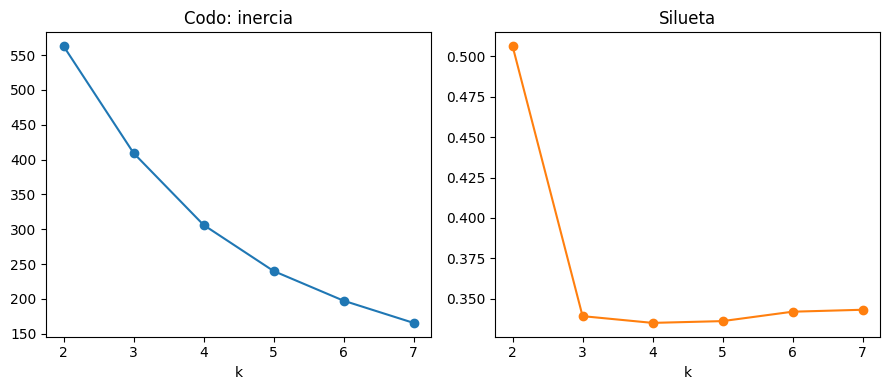

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [ ]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

,consumo_medio,variabilidad,punta,razon_nocturna
grupo,,,,
0,0.782,0.339,1.418,0.638
1,1.442,0.626,2.614,0.636
2,2.606,1.131,4.719,0.639



Tamaño de cada grupo:
grupo
0    132
1     98
2     30


### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

* **razon_nocturna:** Es prácticamente idéntica en los tres grupos (~0.637), por lo que no discrimina entre ellos.
* **consumo_medio, variabilidad y punta:** Aumentan de manera proporcional del grupo 0 al grupo 2.

* **Grupo 0 (132 clientes):** Presenta los valores más bajos en consumo (0.782), variabilidad (0.339) y demanda punta (1.418).
* **Grupo 1 (98 clientes):** Muestra valores intermedios en consumo (1.442), variabilidad (0.626) y punta (2.614).
* **Grupo 2 (30 clientes):** Presenta valores muy altos en consumo (2.606), variabilidad (1.131) y picos de demanda (4.719).

**Nombres propuestos**

- Grupo 0: Consumo bajo y estable con demanda punta moderada.
- Grupo 1: Consumo y variabilidad moderados con picos de demanda intermedios.
- Grupo 2: Alto consumo y alta variabilidad con picos de demanda muy elevados.

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

In [ ]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 97): 2.49
Medidores anómalos: 8 de 260


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,2,4.803
M00074,3.852,1.656,6.983,0.636,2,3.319
M00028,1.002,0.447,1.819,0.610,1,3.187
M00191,3.689,1.606,6.779,0.641,2,2.956
M00041,3.215,1.407,5.848,0.619,2,2.908
M00050,0.744,0.327,1.347,0.614,0,2.864
M00008,0.602,0.262,1.080,0.661,0,2.724
M00097,3.473,1.522,6.326,0.632,2,2.499


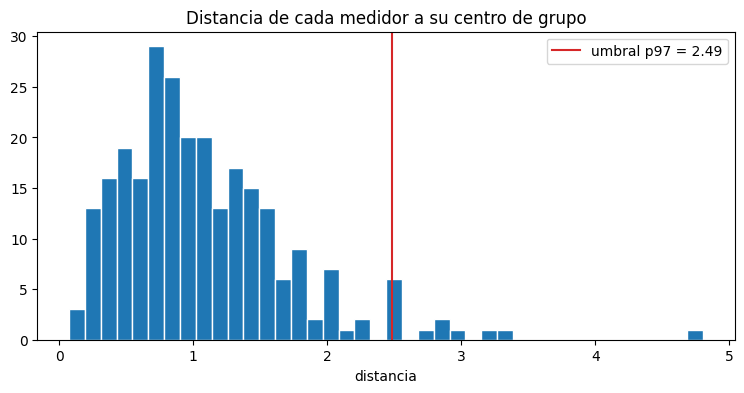

In [ ]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [ ]:
anomalos.sort_values('distancia', ascending=False).round(3).head(3).index

Index(['M00184', 'M00074', 'M00028'], dtype='object', name='medidor_id')

In [ ]:
# Tu código aquí: mira el detalle de esos medidores en el archivo original

top3_medidor_id = anomalos.sort_values('distancia', ascending=False).round(3).head(3).index
grande_top3 = grande[grande['medidor_id'].isin(top3_medidor_id)].sort_values(['medidor_id', 'fecha_hora'])
grande_top3

,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
28,M00028,2025-04-01 00:00:00,Talcahuano,BT1,0.309,3.1,0
288,M00028,2025-04-01 02:00:00,Talcahuano,BT1,0.578,7.9,2
548,M00028,2025-04-01 04:00:00,Talcahuano,BT1,0.444,9.7,4
808,M00028,2025-04-01 06:00:00,Talcahuano,BT1,0.989,9.7,6
1068,M00028,2025-04-01 08:00:00,Talcahuano,BT1,1.374,11.9,8
...,...,...,...,...,...,...,...
279684,M00184,2025-06-29 14:00:00,Los Ángeles,BT2,3.016,11.6,14
279944,M00184,2025-06-29 16:00:00,Los Ángeles,BT2,3.622,9.1,16
280204,M00184,2025-06-29 18:00:00,Los Ángeles,BT2,6.202,6.4,18
280464,M00184,2025-06-29 20:00:00,Los Ángeles,BT2,3.176,6.7,20


In [ ]:
grande_top3.columns

Index(['medidor_id', 'fecha_hora', 'comuna', 'tarifa', 'consumo_kwh',
       'temperatura_c', 'hora'],
      dtype='object')

In [ ]:
# describe sólo los campos de tipo numérico por cada medidor en el top 3
grande_top3.groupby('medidor_id')[
    grande_top3.select_dtypes(include='number').columns
].describe().transpose()

medidor_id                M00028       M00074       M00184
consumo_kwh   count  1080.000000  1080.000000  1080.000000
              mean      1.002319     3.851677     4.326759
              std       0.446892     1.656171     1.882508
              min       0.309000     1.188000     1.267000
              25%       0.642000     2.491500     2.831750
              50%       0.906000     3.512000     3.852500
              75%       1.285500     4.985250     5.419500
              max       2.758000    11.745000    11.628000
temperatura_c count  1080.000000  1080.000000  1080.000000
              mean      8.364722     8.364722     8.364722
              std       3.293933     3.293933     3.293933
              min       0.500000     0.500000     0.500000
              25%       5.775000     5.775000     5.775000
              50%       8.450000     8.450000     8.450000
              75%      10.900000    10.900000    10.900000
              max      17.300000    17.300000    17.300000
hora          count  1080.000000  1080.000000  1080.000000
              mean     11.000000    11.000000    11.000000
              std       6.907304     6.907304     6.907304
              min       0.000000     0.000000     0.000000
              25%       5.500000     5.500000     5.500000
              50%      11.000000    11.000000    11.000000
              75%      16.500000    16.500000    16.500000
              max      22.000000    22.000000    22.000000

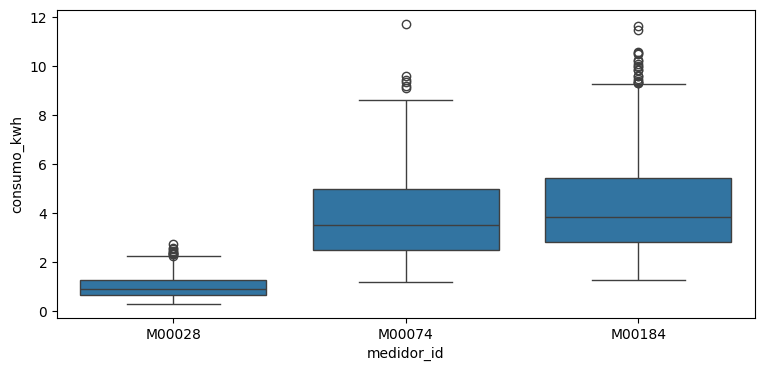

In [ ]:
# boxplot de la variable consumo_kwh por cada medidor en el top 3
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x='medidor_id', y='consumo_kwh', data=grande_top3)
plt.show()

In [ ]:
# columna en grande que sea 'no anómalo' si no es de los medidores top3 y si lo es que su valor sea el medidor_id
grande['class_anomalo'] = grande['medidor_id'].apply(lambda x: x if x in top3_medidor_id else 'no anómalo')

# value_counts de la columna 'class_anomalo'
grande['class_anomalo'].value_counts()

,count
class_anomalo,
no anómalo,277560
M00028,1080
M00074,1080
M00184,1080


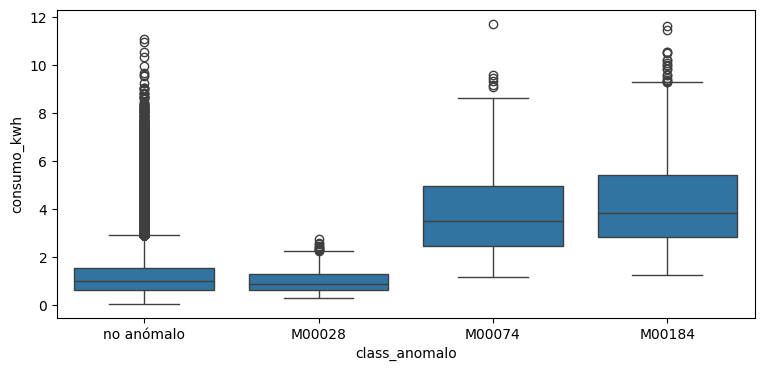

In [ ]:
# boxplot de la variable consumo_kwh por cada class_anomalo
sns.boxplot(x='class_anomalo', y='consumo_kwh', data=grande)
plt.show()

_Tu diagnóstico de los tres casos:_

Observando los diferentes boxplots, las medianas de los medidores M00074 y M00184 están muy por sobre de la mediana del grupo de los "no anómalos", aunque comparando sus outliers se ve que comparten mediciones por sobre los 10 y hasta 12 kWh, por lo que no se podría concluir que sean valores fuera de lo medible, sino simplemente valores muy altos pero posibles.

El caso del medidor M00028 se ve con mediciones levemente más bajas que el grupo "no anómalo" pero destaca más por su mucho más baja variabilidad.



### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

In [ ]:
RUTA_semana3 = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 3/'

In [ ]:
mio = pd.read_csv(RUTA_semana3 + 'mi_conjunto_explorado.csv', sep=';')
print(mio.shape)
mio.head()

(118760, 28)


,idrph,mes_central,fact_anual,conglomerado,estrato,activ,tipo,sexo,edad,orig1,...,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,region_grupo,nacionalidad_grupo,estado_conyugal_grupo,categoria_ocupacion_grupo,edad_edad,meses_ocup_actual_edad
0,966906226666,2,93.924863,20043,13100312,3.0,1,2,75,2.0,...,NaN,2.0,False,Media,Metropolitana,Chilena,Ex pareja,No ocupado,1.0,NaN
1,246247268292,2,102.101514,36033,13100313,1.0,1,1,72,2.0,...,2.0,NaN,NaN,Superior,Metropolitana,Chilena,En pareja,Asalariado,1.0,6.944444
2,254443118268,2,97.354579,36033,13100313,3.0,1,2,61,1.0,...,NaN,2.0,False,Superior,Metropolitana,Chilena,En pareja,No ocupado,1.0,NaN
3,553075369226,2,15.743992,14530,3200110,3.0,1,2,76,1.0,...,NaN,1.0,False,Básica o menos,Norte,Chilena,Soltero/a,No ocupado,1.0,NaN
4,724298626488,2,33.690514,13536,8100312,3.0,1,1,67,2.0,...,NaN,1.0,True,Superior,Biobío y Ñuble,Chilena,En pareja,No ocupado,1.0,NaN


In [ ]:
mio['activ'].value_counts()

,count
activ,
1.0,50106
3.0,45950
2.0,4383


In [ ]:
# Para desarrollar el ejercicio de segmentación correctamente, estudiaremos el subconjunto de los casos con activ = 1
mio_activ = mio[mio['activ'] == 1]
mio_activ

,idrph,mes_central,fact_anual,conglomerado,estrato,activ,tipo,sexo,edad,orig1,...,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,region_grupo,nacionalidad_grupo,estado_conyugal_grupo,categoria_ocupacion_grupo,edad_edad,meses_ocup_actual_edad
1,246247268292,2,102.101514,36033,13100313,1.0,1,1,72,2.0,...,2.0,NaN,NaN,Superior,Metropolitana,Chilena,En pareja,Asalariado,1.0,6.944444
5,255735824251,2,28.088987,13536,8100312,1.0,1,2,64,2.0,...,2.0,NaN,NaN,Media,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,2.562500
8,136336296741,2,39.965080,31039,8100212,1.0,1,1,43,2.0,...,2.0,NaN,NaN,Superior,Biobío y Ñuble,Chilena,Soltero/a,Asalariado,1.0,0.302326
9,528849653300,2,34.130467,31039,8100212,1.0,1,1,57,2.0,...,2.0,NaN,NaN,Superior,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,7.017544
10,363891476705,2,27.970519,31039,8100212,1.0,1,2,57,2.0,...,2.0,NaN,NaN,Superior,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,3.087719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113290,885596239548,11,52.772174,36517,8100213,1.0,1,1,43,2.0,...,2.0,NaN,NaN,Superior,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,2.953488
113291,390223342491,11,44.444407,31712,8100312,1.0,1,1,40,2.0,...,2.0,NaN,NaN,Media,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,0.225000
113292,243543353671,11,43.038756,36814,8100212,1.0,1,2,27,2.0,...,2.0,NaN,NaN,Superior,Biobío y Ñuble,Chilena,Soltero/a,Asalariado,1.0,1.407407
113293,414089553490,11,34.934051,15228,5100212,1.0,1,1,22,2.0,...,NaN,NaN,NaN,Superior,Valparaíso,Chilena,Soltero/a,Asalariado,1.0,NaN


In [ ]:
# variables para segmentar
num_vars = ['edad', 'habituales', 'meses_ocup_actual']

#### 3.1.1 De 50.106 registros con ocupación a 2.520 conglomerados

Las variables numéricas disponibles son características fijas por cada encuestado 'idrph' por lo que este último no sirve para efectos de mostrar una caractarización como lo era con los medidores y sus respectivos consumos en kWh.

En este caso usaremos **conglomerado** como unidad para analizar el comportamiento del campo **'habituales'** que refleja la cantidad horas trabajadas en la semana habitualmente.

In [ ]:
mio_activ['conglomerado'].nunique()

2555

In [ ]:
perfil_2 = mio_activ.groupby('conglomerado').agg(  # agrupa por conglomerado
    habituales_medio=('habituales', 'mean'),  # habituales promedio por conglomerado
    variabilidad=('habituales', 'std'),  # desviación estándar de horas habituales
    punta=('habituales', lambda s: s.quantile(0.95)),  # habituales en punta (percentil 95)
)
verano = mio_activ[mio_activ['mes_central'].isin([2])].groupby('conglomerado')['habituales'].mean()
perfil_2['razon_verano'] = verano / perfil_2['habituales_medio']
perfil_2 = perfil_2.dropna()
print('Perfiles:', perfil_2.shape)
perfil_2.describe().round(3)

Perfiles: (2520, 4)


,habituales_medio,variabilidad,punta,razon_verano
count,2520.000,2520.000,2520.000,2520.000
mean,38.494,11.727,51.661,1.018
std,6.476,5.496,11.062,0.145
min,1.500,0.000,2.000,0.152
25%,35.118,8.377,44.987,0.952
50%,39.302,12.206,48.000,1.012
75%,42.531,15.170,56.000,1.079
max,71.750,33.505,105.000,2.015


In [ ]:
perfil_2

,habituales_medio,variabilidad,punta,razon_verano
conglomerado,,,,
10004,41.000000,2.000000,43.40,0.975610
10008,35.000000,9.601587,44.95,1.051429
10038,42.804878,11.176358,54.00,1.060627
10073,44.333333,0.577350,44.90,1.015038
10127,40.382353,9.751502,46.05,1.002913
...,...,...,...,...
45804,37.083333,11.246269,48.00,1.021723
45805,43.357143,2.214670,45.00,1.008237
45822,42.583333,6.215206,48.00,0.923679


In [ ]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil_2)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0.  0.  0. -0.]
Desviación de cada columna            : [1. 1. 1. 1.]


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.361  inercia=  7415.1  tamaños=[2021  499]
k=3  silueta=0.295  inercia=  5604.4  tamaños=[1085  449  986]
k=4  silueta=0.312  inercia=  4629.4  tamaños=[434 989 394 703]
k=5  silueta=0.280  inercia=  4063.9  tamaños=[951 674 358 190 347]
k=6  silueta=0.276  inercia=  3704.7  tamaños=[833 652 397 187 311 140]
k=7  silueta=0.263  inercia=  3415.4  tamaños=[372 778 375 526 144 189 136]


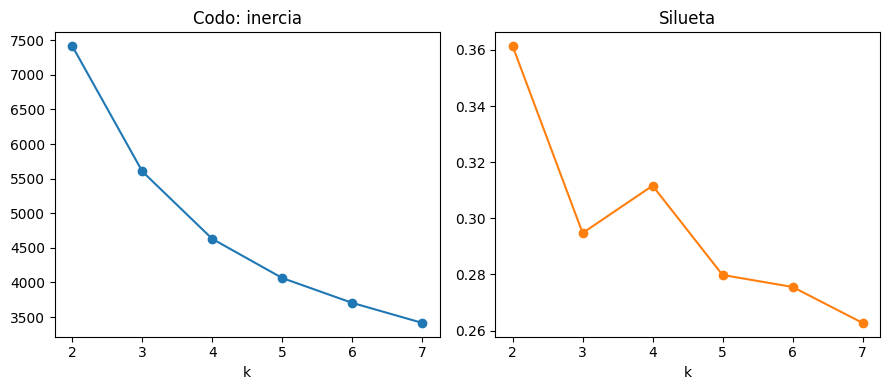

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

La silueta es máxima en **k = 2** (≈ 0,36) y cae a ≈ 0,31 en k = 4; desde ahí baja permanentemente hasta 0,26. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

**Usaré k = 3 asumiendo que puede ser un número plausible de casos subyacentes.**

In [ ]:
km = KMeans(n_clusters=3, random_state=SEMILLA, n_init=10).fit(X)
perfil_2['grupo'] = km.labels_

resumen = perfil_2.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil_2.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil_2['grupo'].value_counts().sort_index().to_string())

,habituales_medio,variabilidad,punta,razon_verano
grupo,,,,
0,33.141,13.924,46.981,1.028
1,43.967,17.471,70.764,1.025
2,41.893,6.695,48.112,1.004



Tamaño de cada grupo:
grupo
0    1085
1     449
2     986


* **razon_verano:** Es prácticamente constante en los tres grupos ($\approx 1,00$ a $1,03$), por lo que **no discrimina** significativamente el comportamiento.

* **habituales_medio, variabilidad y punta:** Muestran diferencias clave entre clústeres:

* **Grupo 0 (1085 clientes):** Presenta el valor de horas habituales más bajo (33,141), una variabilidad moderada (13,924) y una percentil 95 moderado (46,981).
* **Grupo 1 (449 clientes):** Es el de mayor cantidad de horas habituales; registra habituales promedio más alto (43,967), la mayor variabilidad (17.471) y los percentil 95 más elevados (70,764).
* **Grupo 2 (986 clientes):** Tiene horas habituales elevadas (41,893) casi al nivel del Grupo 1, pero se diferencia radicalmente por su **muy baja variabilidad** (6,695) y valores de percentil 95 moderados (48,112).

**Nombres propuestos**

- Grupo 0: Habituales bajas con variabilidad y demanda punta moderadas. (part time horas estables)
- Grupo 1: Alta cantidad de horas habituales con alta variabilidad y picks de demanda muy elevados. (posiblemente horario laboral completo con horas extras a demanda)
- Grupo 2: Alta cantidad de horas habituales, pero con baja variabilidad y picks de demanda moderados. (horario full de oficina practicamente sin necesidades de horas extras)

#### 3.1.2 Detección de anomalías

In [ ]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil_2['distancia'] = distancias

umbral = np.percentile(distancias, 99.7)
anomalos = perfil_2[perfil_2['distancia'] > umbral]
print(f'Umbral (percentil 99.7): {umbral:.2f}')
print(f'Conglomerados anómalos: {len(anomalos)} de {len(perfil_2)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 99.7): 5.67
Conglomerados anómalos: 8 de 2520


,habituales_medio,variabilidad,punta,razon_verano,grupo,distancia
conglomerado,,,,,,
21425,1.500,0.577,2.00,1.333,0,7.124
27819,13.200,10.085,25.20,0.152,0,7.103
37751,21.833,14.784,41.75,2.015,0,7.045
17054,24.667,20.817,45.00,1.946,0,6.586
21931,16.400,10.139,28.80,1.829,0,6.355
29464,16.500,12.369,29.10,1.818,0,6.243
16135,17.200,16.468,39.20,0.233,0,6.076
12451,12.667,6.110,17.60,0.474,0,5.808


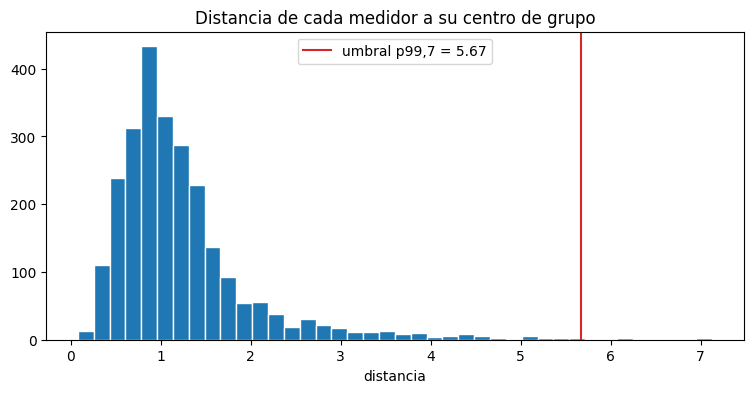

In [ ]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p99,7 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

In [ ]:
top3_conglomerado = anomalos.sort_values('distancia', ascending=False).round(3).head(3).index
mio_activ_top3 = mio_activ[mio_activ['conglomerado'].isin(top3_conglomerado)].sort_values(['conglomerado', 'mes_central'])
mio_activ_top3

,idrph,mes_central,fact_anual,conglomerado,estrato,activ,tipo,sexo,edad,orig1,...,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,region_grupo,nacionalidad_grupo,estado_conyugal_grupo,categoria_ocupacion_grupo,edad_edad,meses_ocup_actual_edad
6748,36395548,2,25.229799,21425,14100210,1.0,1,1,48,2.0,...,2.0,NaN,NaN,Media,Sur,Chilena,Soltero/a,Independiente,1.0,4.958333
52737,36395548,5,26.686184,21425,14100210,1.0,1,1,49,2.0,...,2.0,NaN,NaN,Media,Sur,Chilena,Soltero/a,Asalariado,1.0,4.918367
80998,36395548,8,24.021960,21425,14100210,1.0,1,1,49,2.0,...,2.0,NaN,NaN,Media,Sur,Chilena,Soltero/a,Independiente,1.0,4.979592
110692,36395548,11,23.783398,21425,14100210,1.0,1,1,49,2.0,...,2.0,NaN,NaN,Media,Sur,Chilena,Soltero/a,Independiente,1.0,1.857143
3019,235735740714,2,103.290318,27819,13300210,1.0,1,2,43,2.0,...,1.0,NaN,NaN,Media,Metropolitana,Chilena,Soltero/a,Independiente,1.0,0.069767
30083,206172276308,5,84.206928,27819,13300210,1.0,1,1,62,2.0,...,2.0,NaN,NaN,Básica o menos,Metropolitana,Chilena,En pareja,Independiente,1.0,1.338710
44107,937735196396,5,91.879140,27819,13300210,1.0,1,2,24,2.0,...,2.0,NaN,NaN,Media,Metropolitana,Chilena,Soltero/a,Independiente,1.0,0.250000
59442,206172276308,8,87.961734,27819,13300210,1.0,1,1,63,2.0,...,2.0,NaN,NaN,Básica o menos,Metropolitana,Chilena,En pareja,Independiente,1.0,2.888889
90410,206172276308,11,88.169798,27819,13300210,1.0,1,1,63,2.0,...,2.0,NaN,NaN,Básica o menos,Metropolitana,Chilena,En pareja,Independiente,1.0,3.888889
13117,726200110925,2,24.809113,37751,16200120,1.0,3,1,38,2.0,...,2.0,NaN,NaN,Básica o menos,Biobío y Ñuble,Chilena,En pareja,Asalariado,1.0,0.868421


In [ ]:
# columna en mio_activ que sea 'no anómalo' si no es de los conglomerados top3 y si lo es que su valor sea el conglomerado
mio_activ['class_anomalo'] = mio_activ['conglomerado'].apply(lambda x: x if x in top3_conglomerado else 'no anómalo')

# value_counts de la columna 'class_anomalo'
mio_activ['class_anomalo'].value_counts()

/tmp/ipykernel_10854/3401780568.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mio_activ['class_anomalo'] = mio_activ['conglomerado'].apply(lambda x: x if x in top3_conglomerado else 'no anómalo')


,count
class_anomalo,
no anómalo,50091
37751,6
27819,5
21425,4


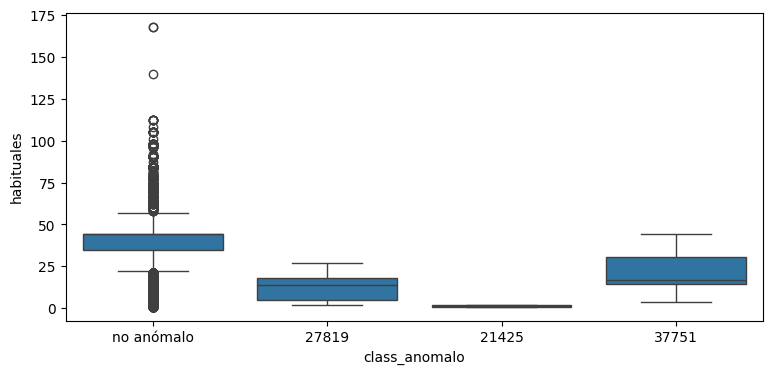

In [ ]:
# boxplot de la variable consumo_kwh por cada class_anomalo
sns.boxplot(x='class_anomalo', y='habituales', data=mio_activ)
plt.show()

_Tu diagnóstico de los tres casos:_

Observando los diferentes boxplots, las medianas de los conglomerados 27819 y 37751 están muy por debajo de la mediana del grupo de los "no anómalos", aunque no se podría concluir que sean valores fuera de lo medible, sino simplemente valores muy bajos pero posibles.

El caso del conglomerado 21425 se ve con horas habituales drásticamente más bajas que el grupo "no anómalo", incluso muy cercanas a cero, pero además destaca más por su variabilidad casi nula.

_Tu lectura de los grupos y de las anomalías de tu conjunto:_



---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor

def comparar(y, columnas, titulo):
    Xv = perfil[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar(perfil['punta'],
         ['consumo_medio', 'variabilidad', 'razon_nocturna'],
         'A · Predecir la PUNTA de consumo')
comparar(perfil['razon_nocturna'],
         ['consumo_medio', 'variabilidad', 'punta'],
         'B · Predecir la RAZÓN NOCTURNA')

A · Predecir la PUNTA de consumo
 profundidad   R² train    R² test
           2      0.892      0.853
           4      0.994      0.984
           8      1.000      0.997
          16      1.000      0.992
        None      1.000      0.992

B · Predecir la RAZÓN NOCTURNA
 profundidad   R² train    R² test
           2      0.060     -0.078
           4      0.182     -0.070
           8      0.569     -0.280
          16      0.970     -0.890
        None      1.000     -0.919



### Lo que muestran las dos tablas

**Caso A — hay relación.** El R² de entrenamiento sube a 1,00 y el de prueba lo acompaña, quedándose en torno a 0,99. El modelo aprendió algo que también vale fuera de los datos con que aprendió.

**Caso B — no hay relación.** Mira la columna de la derecha: el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,9 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a **1,000**: perfecto.

> **Un R² negativo significa que el modelo predice peor que decir siempre el promedio.** Y aun así, sobre los datos de entrenamiento acierta todo. Eso es exactamente el sobreajuste: el árbol no encontró un patrón, **memorizó las filas**.

La lección práctica: si alguien te presenta un modelo con 98 % de acierto y no te dice sobre qué datos se midió, la cifra no significa nada. Un modelo siempre puede memorizar sus propios datos.

### 4.2 Validación cruzada

Una sola partición puede tocarte fácil o difícil por azar. La validación cruzada parte los datos en k pliegues, entrena k veces y promedia. Lo valioso no es solo la media: es la **desviación**, que dice cuán estable es el resultado.

In [ ]:
for etiqueta, y, cols in [
    ('A · punta         ', perfil['punta'],          ['consumo_medio', 'variabilidad', 'razon_nocturna']),
    ('B · razón nocturna', perfil['razon_nocturna'], ['consumo_medio', 'variabilidad', 'punta']),
]:
    for prof in (2, None):
        s = cross_val_score(DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA),
                            perfil[cols], y, cv=5, scoring='r2')
        print(f'{etiqueta}  prof={str(prof):>4s}  R² = {s.mean():7.3f} ± {s.std():.3f}   '
              f'pliegues {np.round(s, 2)}')

A · punta           prof=   2  R² =   0.849 ± 0.019   pliegues [0.82 0.87 0.87 0.83 0.85]
A · punta           prof=None  R² =   0.994 ± 0.003   pliegues [1.   1.   0.99 0.99 0.99]
B · razón nocturna  prof=   2  R² =  -0.104 ± 0.056   pliegues [-0.08 -0.19 -0.03 -0.07 -0.15]
B · razón nocturna  prof=None  R² =  -0.830 ± 0.250   pliegues [-0.35 -0.95 -0.9  -1.08 -0.86]


Dos lecturas:

- El caso A con profundidad ilimitada entrega **0,994 ± 0,003**: estable en los cinco pliegues.
- El caso B con profundidad ilimitada entrega algo como **−0,83 ± 0,25**. No solo es malo: es **inestable**. Según qué pliegue te toque, el resultado cambia mucho.

> **Reporta siempre media y desviación.** Un 0,80 ± 0,03 y un 0,80 ± 0,25 son resultados muy distintos, y el segundo no sostiene ninguna decisión.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

In [ ]:
siluetas = []
for i in range(20):
    idx = np.random.RandomState(SEMILLA + i).choice(len(X), int(len(X) * 0.8), replace=False)
    km_i = KMeans(n_clusters=3, random_state=SEMILLA + i, n_init=10).fit(X[idx])
    siluetas.append(silhouette_score(X[idx], km_i.labels_))

siluetas = np.array(siluetas)
print(f'Silueta sobre 20 submuestras del 80 %: {siluetas.mean():.3f} ± {siluetas.std():.3f}')
print(f'Rango: [{siluetas.min():.3f}, {siluetas.max():.3f}]')

Silueta sobre 20 submuestras del 80 %: 0.297 ± 0.002
Rango: [0.292, 0.301]


### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

In [ ]:
perfil_2

,habituales_medio,variabilidad,punta,razon_verano,grupo,distancia
conglomerado,,,,,,
10004,41.000000,2.000000,43.40,0.975610,2,0.983916
10008,35.000000,9.601587,44.95,1.051429,0,0.871195
10038,42.804878,11.176358,54.00,1.060627,2,1.058851
10073,44.333333,0.577350,44.90,1.015038,2,1.212078
10127,40.382353,9.751502,46.05,1.002913,2,0.632265
...,...,...,...,...,...,...
45804,37.083333,11.246269,48.00,1.021723,0,0.785696
45805,43.357143,2.214670,45.00,1.008237,2,0.891173
45822,42.583333,6.215206,48.00,0.923679,2,0.572432


In [ ]:
def comparar_2(y, columnas, titulo):
    Xv = perfil_2[columnas]
    X_tr, X_te, y_tr, y_te = train_test_split(Xv, y, test_size=0.3, random_state=SEMILLA)
    print(titulo)
    print(f"{'profundidad':>12s} {'R² train':>10s} {'R² test':>10s}")
    for prof in (2, 4, 8, 16, None):
        m = DecisionTreeRegressor(max_depth=prof, random_state=SEMILLA).fit(X_tr, y_tr)
        print(f'{str(prof):>12s} {m.score(X_tr, y_tr):10.3f} {m.score(X_te, y_te):10.3f}')
    print()

comparar_2(perfil_2['razon_verano'],
         ['habituales_medio', 'variabilidad', 'punta'],
         'Predecir la razon_verano a partir de las otras variables')

Predecir la razon_verano a partir de las otras variables
 profundidad   R² train    R² test
           2      0.039     -0.042
           4      0.087     -0.011
           8      0.190     -0.060
          16      0.491     -0.459
        None      0.996     -0.989



**No hay relación.** En la columna de la derecha el R² de prueba es **negativo** y empeora a medida que el árbol se hace más profundo, hasta cerca de −0,99 con profundidad ilimitada. Mientras tanto, el de entrenamiento llega a casi 1.

_Tu estimación de robustez y tu conclusión:_



---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [ ]:
import os, time

ruta = RUTA + '7-S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

Tamaño en disco: 13.2 MB


### Estrategia A · leer todo

In [ ]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Tiempo: 0.50 s · Memoria: 68.0 MB · Filas: 280,800


Fíjate: **13 MB en disco se convierten en unos 78 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

### Estrategia B · leer solo las columnas necesarias

In [ ]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

Tiempo: 0.29 s · Memoria: 16.9 MB
Reducción de memoria: 75 %


### Estrategia C · procesar por bloques

In [ ]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

Tiempo: 0.66 s · Memoria máxima: la de UN bloque, no la del archivo
Medidores agregados: 260


In [ ]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

¿Mismo resultado? True


### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [ ]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

A · todo el archivo :  0.50 s ·   68.0 MB
B · dos columnas    :  0.29 s ·   16.9 MB
C · por bloques     :  0.66 s · memoria acotada al bloque


### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

_Tu respuesta:_

1. ¿A partir de qué tamaño de archivo cambiaría de estrategia y por qué?

El cambio de estrategia debe realizarse cuando el archivo en disco alcanza aproximadamente entre 2 y 2,5 GB. Esto ocurre porque al cargar un archivo plano como un CSV, los datos se expanden en la memoria RAM entre 5 y 6 veces su peso en disco. Dado que Google Colab dispone de unos 12 GB de memoria RAM, un archivo de 2,5 GB superaría los 12 GB en memoria y provocaría un colapso del sistema por falta de memoria. El propósito del procesamiento por bloques o selección de columnas no es aumentar la velocidad de ejecución, sino hacer técnicamente posible la lectura sin exceder el límite de memoria.

2. Cálculo del consumo medio por comuna en un archivo de 40 GB (paso a paso):

Paso 1: Filtrar las columnas al leer el archivo con el parámetro usecols, cargando únicamente la columna de comuna y la de consumo para minimizar el uso de memoria por registro.

Paso 2: Aplicar la lectura por bloques mediante el parámetro chunksize (por ejemplo, fragmentos de 50.000 filas) para procesar el archivo en partes sin desbordar la memoria RAM.

Paso 3: Extraer en cada bloque dos valores por comuna: la suma acumulada del consumo (sum) y el conteo de registros (count). No se deben promediar los promedios parciales de los bloques para evitar sesgos numéricos.

Paso 4: Unir los resultados parciales de todos los bloques, sumar los totales acumulados por comuna y dividir la suma total entre el conteo total acumulado para obtener el consumo medio exacto.

---
## Cierre y versionado

In [ ]:
# mio.to_csv(RUTA + 'mi_conjunto_minado.csv', sep=';', index=False)
# print('Guardado')

In [ ]:
# En una terminal:
# git add S4_Notebook_Laboratorio_CDD.ipynb mi_conjunto_minado.csv
# git commit -m 'Semana 4: mineria, validacion y volumen'
# git push


**Enlace a mi repositorio:** [https://github.com/hersil7/cdd_ucsc](https://github.com/hersil7/cdd_ucsc)

---

## Antes de entregar

- [ ] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [ ] Los grupos obtenidos tienen nombre descriptivo, no número
- [ ] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [ ] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [ ] Comparación del costo computacional de dos estrategias, con cifras propias
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_